## 🐻‍❄️ 투빅스 25&26기 - 추천시스템 & GNN 과제 [MovieLens로 BPR-MF, NeuMF, LightGCN 직접 구현]

#### ✅ 과제 목적
세션에서 배운 추천의 흐름 - **시청 기록 → 평가 지표 → 벡터(임베딩)로 학습 → 그래프로 연결 전파** - 를 실제 데이터로 따라갑니다.
라이브러리의 완성된 모델을 불러오는 대신, 세션 슬라이드에 나온 **식을 직접 코드로 옮겨** 네 가지 추천 방법을 같은 조건에서 비교합니다.

> - **Part A. 직접 구현하고 비교하기 (필수)** - 평가 지표, 인기순, Item-CF, BPR-MF, NeuMF, LightGCN을 차례로 구현하고 Recall@20, NDCG@20으로 비교합니다.
> - **Part B. 세션의 주장을 검증하기 (심화 선택)** - "층은 깊을수록 좋은가?", "W와 σ를 빼니 더 좋아졌다", "정규화가 인기 편향을 줄이는가?"를 본인 실험으로 확인합니다.

#### 📝 기술블로그 활용 방안 (필수 확인)
이 과제의 실험, 코드, 해석은 **기술블로그 글의 재료**입니다. 아래 항목은 노트북에서 끝내지 말고 **기술블로그에 옮겨 작성**해 주세요.

| 블로그에 옮길 내용 | 노트북 위치 |
|---|---|
| ① MovieLens의 희소성 수치와 Long-tail 그래프, 그리고 "빈칸 = 모름"에 대한 본인 해석 | 1장, 서술형 문제 1 |
| ② 직접 구현한 Recall@K, NDCG@K 코드와, 세션 예시(0.40 / 0.67 / 0.70)로 검증한 과정 | 2장 |
| ③ BPR 손실, Negative Sampling, LightGCN 정규화, 전파 코드를 **식과 함께** 설명 | 4장, 6장 |
| ④ **네 모델 비교 표, 막대그래프와 해석** (가장 중요) | 7장, 서술형 문제 2, 3 |
| ⑤ (심화 선택) 층 수 실험, W/σ 실험, 인기 편향 실험의 그래프와, 세션 주장과 **같았는지 / 달랐는지**에 대한 해석 | Part B, 서술형 문제 4, 5, 6 |

> 블로그에는 **본인 시드로 나온 숫자와 그래프를 그대로** 쓰고, 결과가 세션 슬라이드와 다르게 나왔다면 그 이유를 추론해 함께 적어 주세요.

> **데이터셋:** [MovieLens-100K](https://grouplens.org/datasets/movielens/100k/) (GroupLens) - [RecBole 저장소](https://github.com/RUCAIBox/RecBole)의 사본을 내려받아 사용합니다.
> - 사용자 943명, 영화 1,682편, 별점 100,000개
> - 세션처럼 **암묵적 피드백**으로 바꿔 씁니다: 별점 4점 이상 = "봤다(좋아했다)", 나머지와 기록 없음 = 빈칸

#### ✅ 주의 사항
- **런타임 > 런타임 유형 변경 > GPU**를 켜고 시작하세요. (CPU로도 돌아가지만 Part B가 느립니다)
- `# ===== TODO n =====` 블록 안만 채우세요. 나머지 셀은 준비 코드이므로 수정하지 않습니다.
- `MY_SEED`(학번 뒷 4자리)에 따라 데이터 분할이 달라져 **사람마다 숫자가 조금씩 다릅니다.** 정상입니다.
- 각 TODO 아래의 `✅ 확인` 셀이 통과해야 다음으로 넘어갈 수 있습니다.

### 🗺️ 실습 흐름

> **Part A. 직접 구현하고 비교하기 (필수)**
0. 환경 설정
1. 데이터 만나기 - 상호작용 행렬, Sparsity, Long-tail
2. 채점 방법 만들기 - Recall@K, NDCG@K 직접 구현
3. 기준 모델 - 인기순 추천, Item-CF (Jaccard)
4. BPR-MF - 내적 점수, Negative Sampling, BPR 손실
5. NeuMF - 내적 대신 신경망
6. LightGCN - 정규화 인접행렬, 층별 전파, 층 평균
7. 네 모델 비교 + 내 시드의 사용자에게 추천된 영화 보기

> **Part B. 세션의 주장을 검증하기 (심화 선택)**
8. 층은 깊을수록 좋을까? - 층 수 실험 & Over-smoothing 측정
9. W와 σ를 다시 넣으면? - LightGCN vs NGCF 스타일
10. 정규화는 인기 편향을 줄일까? - 추천 결과의 인기도 분석

### 📖 세션 슬라이드 대응표

| 노트북 | 세션 슬라이드 |
|---|---|
| 1장 상호작용 행렬, Sparsity, Long-tail | 6~8p 데이터 이해하기, 14p 추천의 어려움 |
| 2장 Recall@K, NDCG@K | 9p 평가 방법 |
| 3장 인기순, Item-CF | 13p Item-based CF (Jaccard), 14p 인기 편향 |
| 4장 BPR-MF | 17~18p MF와 내적, 20p BPR과 Negative Sampling |
| 5장 NeuMF | 21p NCF |
| 6장 LightGCN | 25p 이분 그래프, 39~40p LightGCN 동작 방식 |
| 8장 층 수, Over-smoothing | 31p Over-smoothing, 41p 층 수 실험 |
| 9장 W와 σ | 33p GCN, 38p NGCF → LightGCN |
| 10장 인기 편향 | 14p 인기 편향, 39p 정규화 |

# 🧭 Part A. 직접 구현하고 비교하기 (필수)

### ⚙️ 0. 환경 설정 - 라이브러리, 학생별 시드, 실험 설정

In [1]:
import os, math, random, time, urllib.request

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # torch sparse 경고 숨김

# ---- 실험 설정 (모든 모델이 같은 조건) ----
EMB_DIM = 64          # 임베딩 길이
TOPK = 20             # Recall@20, NDCG@20
EPOCHS = 50          # 모델별 학습 epoch
BATCH_SIZE = 2048
LR = 5e-3
REG = 1e-4            # 임베딩 L2 정규화 계수
N_LAYERS = 3          # LightGCN 기본 층 수
POS_THRESHOLD = 4     # 별점 4점 이상 = 상호작용(봤다)

# ===== TODO 0 =====
# 힌트: 본인 학번 뒷 4자리를 넣으세요. (예: 202612345 -> 2345)
MY_SEED = 1352   # TODO: 학번 뒷 4자리
# ==================

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

assert MY_SEED is not None, "TODO 0: MY_SEED에 학번 뒷 4자리를 넣으세요."
set_seed(MY_SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device  :", device)
print("MY_SEED :", MY_SEED)
if device == "cpu":
    print("\n⚠️ GPU가 아닙니다. 런타임 > 런타임 유형 변경에서 GPU를 켜세요.")

device  : cuda
MY_SEED : 1352


### 📦 1. 데이터 만나기 - 상호작용 행렬, Sparsity, Long-tail

세션 7p처럼 시청 기록을 **사용자 × 영화 표**로 바꿉니다. 별점 4점 이상만 "봤다(1)"로 남기고, 나머지는 빈칸입니다.

In [2]:
# ---- MovieLens-100K 다운로드 (준비 코드) ----
# GroupLens 원본과 같은 데이터를 RecBole 공식 저장소의 사본에서 받습니다.
# (Colab에서 GroupLens 서버는 SSL 인증서 오류로 다운로드가 실패하는 경우가 있습니다)
BASE = "https://raw.githubusercontent.com/RUCAIBox/RecBole/master/dataset/ml-100k/"
for f in ["ml-100k.inter", "ml-100k.item"]:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + f, f)

ratings = pd.read_csv("ml-100k.inter", sep="\t")
ratings.columns = ["user", "item", "rating", "ts"]
titles = pd.read_csv("ml-100k.item", sep="\t", usecols=[0, 1])
titles.columns = ["item", "title"]

# 암묵적 피드백으로 변환: 별점 4점 이상만 상호작용으로 사용
inter = ratings[ratings.rating >= POS_THRESHOLD][["user", "item"]].drop_duplicates()

# 사용자 / 영화 번호를 0부터 다시 매기기
uid = {u: k for k, u in enumerate(sorted(inter.user.unique()))}
iid = {i: k for k, i in enumerate(sorted(inter.item.unique()))}
inter = inter.assign(u=inter.user.map(uid), i=inter.item.map(iid))
idx2title = dict(zip(titles.item.map(iid), titles.title))
n_users, n_items = len(uid), len(iid)

print("원본 별점 수        :", len(ratings))
print("상호작용 수 (4점↑) :", len(inter))
print("사용자 수 × 영화 수 : %d × %d" % (n_users, n_items))

원본 별점 수        : 100000
상호작용 수 (4점↑) : 55375
사용자 수 × 영화 수 : 942 × 1447


#### ✏️ ===== TODO 1 =====
세션 8p처럼 **빈칸 비율(Sparsity)** 을 구하세요. Sparsity = 1 − (상호작용 수 ÷ 전체 칸 수)

In [3]:
# ===== TODO 1 =====
# 힌트: 전체 칸 수 = n_users * n_items
sparsity = 1 - len(inter) / (n_users * n_items)
# ==================

# ✅ 확인
assert sparsity is not None and 0.9 < sparsity < 1.0, "Sparsity 계산을 다시 확인하세요."
print("Sparsity: %.2f%%  (세션 예시 MovieLens-1M은 약 95.5%%)" % (sparsity * 100))
print("✅ 통과")

Sparsity: 95.94%  (세션 예시 MovieLens-1M은 약 95.5%)
✅ 통과


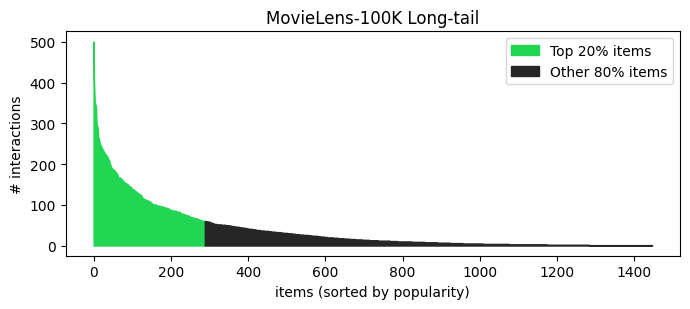

상위 20%의 영화가 전체 상호작용의 69.0%를 차지


In [4]:
# ---- Long-tail 그래프 (준비 코드) ----
item_cnt = inter.i.value_counts().sort_values(ascending=False).values
head_n = int(len(item_cnt) * 0.2)
share = item_cnt[:head_n].sum() / item_cnt.sum()

plt.figure(figsize=(7, 3.2))
plt.fill_between(range(head_n), item_cnt[:head_n], color="#22D654", label="Top 20% items")
plt.fill_between(range(head_n - 1, len(item_cnt)), item_cnt[head_n - 1:], color="#262626", label="Other 80% items")
plt.xlabel("items (sorted by popularity)"); plt.ylabel("# interactions"); plt.legend()
plt.title("MovieLens-100K Long-tail"); plt.tight_layout(); plt.show()
print("상위 20%%의 영화가 전체 상호작용의 %.1f%%를 차지" % (share * 100))

#### 📝 서술형 문제 1
1. 본인의 Sparsity 값과 Long-tail 그래프의 "상위 20% 비율"을 인용하세요.
2. 이 데이터에서 빈칸이 "싫어서 안 본 것"이 아니라 "아직 모르는 것"으로 봐야 하는 이유를, 우리가 별점 4점 미만을 **빈칸으로 처리했다**는 사실과 연결해 설명하세요. (이 처리 방식의 한계도 한 가지 적어 보세요.)


계산된 Sparsity는 95.94%로, 전체 사용자–영화 조합 중 약 4.06%에만 별점 4점 이상의 상호작용이 존재한다. 인기 상위 20%의 영화가 전체 상호작용의 69.0%를 차지한다. 그래프에서도 소수의 인기 영화에 상호작용이 집중되고, 나머지 다수의 영화는 상호작용이 적은 Long-tail 분포를 확인할 수 있다. 이 데이터의 빈칸은 사용자가 영화를 싫어해서 보지 않았다는 뜻으로 단정할 수 없다. 영화를 접하지 못했거나, 시청했지만 별점을 남기지 않았을 수도 있기 때문이다. 또한 이번 전처리에서는 별점 4점 미만의 기록도 빈칸으로 처리했으므로, 빈칸에는 ‘평가 기록이 없는 경우’와 ‘평가했지만 4점 미만을 준 경우’가 함께 섞여 있다. 따라서 빈칸은 확실한 비선호가 아니라, 이진화된 데이터만으로는 선호 여부를 확정할 수 없는 상태로 해석해야 한다. 이 처리 방식의 한계는 낮은 별점에 담긴 부정적 평가나 선호 강도 정보가 사라져, 이를 미평가 상태와 구분할 수 없다는 점이다.

### 🎯 2. 채점 방법 만들기 - Recall@K, NDCG@K

세션 9p처럼 **기록 일부를 숨겨두고**(test), 모델이 추천한 상위 K개 안에 다시 나오는지 확인합니다.
분할은 사용자마다 기록의 20%를 test로 숨기며, `MY_SEED`에 따라 달라집니다.

In [5]:
# ---- train / test 분할 (준비 코드): 사용자마다 20%를 test로 ----
rng = np.random.default_rng(MY_SEED)
train_rows, test_rows = [], []
for u, g in inter.groupby("u"):
    items = g.i.values.copy(); rng.shuffle(items)
    n_test = max(1, int(round(len(items) * 0.2))) if len(items) >= 5 else 0
    test_rows += [(u, i) for i in items[:n_test]]
    train_rows += [(u, i) for i in items[n_test:]]
train_df = pd.DataFrame(train_rows, columns=["u", "i"])
test_df = pd.DataFrame(test_rows, columns=["u", "i"])

train_items = train_df.groupby("u").i.apply(set).to_dict()            # 사용자별 학습 기록
test_items = test_df.groupby("u").i.apply(set).to_dict()              # 사용자별 정답(숨긴 기록)
train_u = torch.tensor(train_df.u.values); train_i = torch.tensor(train_df.i.values)
train_mask = torch.zeros(n_users, n_items, dtype=torch.bool)   # 학습 때 본 영화면 True
train_mask[train_u, train_i] = True
print("train 상호작용: %d / test 상호작용: %d / 평가 대상 사용자: %d" % (len(train_df), len(test_df), len(test_items)))

train 상호작용: 44300 / test 상호작용: 11075 / 평가 대상 사용자: 938


#### ✏️ ===== TODO 2 =====
한 사용자의 추천 목록 `ranked`(점수 높은 순, 길이 K)와 정답 집합 `truth`로 **Recall@K**와 **NDCG@K**를 구하는 함수를 완성하세요.

- Recall@K = 상위 K개 안에서 찾은 정답 수 ÷ 정답 수
- NDCG@K = DCG ÷ IDCG,  DCG = Σ (정답이면 1) / log₂(순위 + 1),  IDCG = 정답을 모두 맨 위에 놓았을 때의 DCG

In [6]:
def recall_at_k(ranked, truth):
    # ===== TODO 2-1 =====
    return len(set(ranked) & set(truth)) / len(truth) if len(truth) > 0 else 0.0
    # ==================


def ndcg_at_k(ranked, truth):
    # ===== TODO 2-2 =====
    dcg = sum(
        1 / math.log2(r + 1)
        for r, item in enumerate(ranked, start=1)
        if item in truth
    )
    idcg = sum(
        1 / math.log2(r + 1)
        for r in range(1, min(len(truth), len(ranked)) + 1)
    )
    return dcg / idcg if idcg > 0 else 0.0
    # ==================

# ✅ 확인 - 세션 9p 예시 그대로: 정답 3개, 추천 5개 중 1등과 3등이 정답
ranked = ["매트릭스", "라라랜드", "테넷", "어바웃 타임", "아바타"]
truth = {"매트릭스", "테넷", "덩케르크"}
r, n = recall_at_k(ranked, truth), ndcg_at_k(ranked, truth)
assert r is not None and n is not None, "TODO 2를 완성하세요."
print("Recall@5 = %.2f (세션: 0.67) / NDCG@5 = %.3f (세션: 0.70)" % (r, n))
assert abs(r - 2 / 3) < 1e-6 and abs(n - 0.7039) < 1e-3, "세션 예시와 값이 다릅니다."
print("✅ 통과")

Recall@5 = 0.67 (세션: 0.67) / NDCG@5 = 0.704 (세션: 0.70)
✅ 통과


In [7]:
# ---- 전체 평가 함수 (준비 코드): 학습 때 본 영화는 후보에서 제외하고 Top-K 추출 ----
@torch.no_grad()
def evaluate(score_fn, k=TOPK, return_lists=False):
    # score_fn(user_idx_tensor) -> (len(users), n_items) 점수 행렬
    users = sorted(test_items.keys())
    recalls, ndcgs, rec_lists = [], [], {}
    for s in range(0, len(users), 256):
        batch = users[s:s + 256]
        scores = score_fn(torch.tensor(batch, device=device)).float().cpu()
        for row, u in enumerate(batch):
            seen = list(train_items.get(u, ()))
            scores[row, seen] = -float("inf")
        top = torch.topk(scores, k, dim=1).indices.numpy()
        for row, u in enumerate(batch):
            ranked = top[row].tolist()
            recalls.append(recall_at_k(ranked, test_items[u]))
            ndcgs.append(ndcg_at_k(ranked, test_items[u]))
            rec_lists[u] = ranked
    out = {"Recall@%d" % k: float(np.mean(recalls)), "NDCG@%d" % k: float(np.mean(ndcgs))}
    return (out, rec_lists) if return_lists else out

results = {}   # 모델별 결과를 모아 7장에서 비교합니다

### 📏 3. 기준 모델 - 인기순 추천, Item-CF

복잡한 모델을 만들기 전에 **기준선**부터 잽니다. 이 기준선을 못 넘으면 모델을 쓸 이유가 없습니다.

#### ✏️ ===== TODO 3 =====
**인기순 추천**: 모든 사용자에게 학습 데이터에서 가장 많이 본 영화부터 추천합니다. 영화별 상호작용 수 `pop`을 구하세요.

In [8]:
# ===== TODO 3 =====
pop = torch.bincount(train_i, minlength=n_items)
# ==================

assert pop is not None, "TODO 3을 완성하세요."
results["Popularity"] = evaluate(lambda users: pop.to(device).unsqueeze(0).repeat(len(users), 1))
print(results["Popularity"])

{'Recall@20': 0.18696812099187568, 'NDCG@20': 0.16562914480104104}


#### ✏️ ===== TODO 4 =====
세션 13p의 **Item-CF (Jaccard)** 입니다. 두 영화를 모두 본 사람 수 ÷ 둘 중 하나라도 본 사람 수.

`R`은 사용자 × 영화 0/1 행렬입니다. `co = Rᵀ R`의 (a, b) 칸은 a와 b를 **모두 본 사람 수**입니다.
사용자 점수는 "내가 본 영화들과의 Jaccard 유사도 합"으로 계산합니다.

In [9]:
R = torch.zeros(n_users, n_items)
R[train_u, train_i] = 1.0
co = R.T @ R                      # (n_items, n_items) 모두 본 사람 수
deg = R.sum(0)                    # 영화별 본 사람 수

# ===== TODO 4 =====
union = deg.unsqueeze(1) + deg.unsqueeze(0) - co
jaccard = co / union.clamp(min=1)
jaccard.fill_diagonal_(0)
# ==================

assert jaccard is not None, "TODO 4를 완성하세요."
R_dev, J_dev = R.to(device), jaccard.to(device)
results["Item-CF"] = evaluate(lambda users: R_dev[users] @ J_dev)
print(results["Item-CF"])

{'Recall@20': 0.2833306170766833, 'NDCG@20': 0.2633134743551178}


### 🧠 4. BPR-MF - 내적 점수, Negative Sampling, BPR 손실

세션 18p, 20p를 그대로 코드로 옮깁니다.
- 점수: **ŷ = 사용자 벡터와 영화 벡터의 내적**
- 학습: 시청 기록에는 '싫어요'가 없으므로, **본 영화(pos)를 안 본 영화(neg)보다 선호한다고 가정**하고 순서를 학습합니다.
- `L = − mean( ln σ(ŷ_pos − ŷ_neg) )` (+ 임베딩 L2 정규화)

#### ✏️ ===== TODO 5, 6, 7 =====

In [10]:
def sample_batch(batch_size):
    # 학습 상호작용에서 (user, pos)를 뽑고, 각 user가 보지 않은 영화를 neg로 하나씩 뽑습니다.
    idx = torch.randint(0, len(train_u), (batch_size,))
    users, pos = train_u[idx], train_i[idx]
     # ===== TODO 5 =====
    neg = torch.randint(0, n_items, (batch_size,))

    mask = train_mask[users, neg]
    while mask.any():
        neg[mask] = torch.randint(0, n_items, (mask.sum().item(),))
        mask = train_mask[users, neg]
    # ==================
    return users.to(device), pos.to(device), neg.to(device)


def bpr_loss(pos_score, neg_score):
    # ===== TODO 6 =====
    return -F.logsigmoid(pos_score - neg_score).mean()
    # ==================
    # ==================


class MF(nn.Module):
    def __init__(self):
        super().__init__()
        self.user_emb = nn.Embedding(n_users, EMB_DIM)
        self.item_emb = nn.Embedding(n_items, EMB_DIM)
        nn.init.normal_(self.user_emb.weight, std=0.1)
        nn.init.normal_(self.item_emb.weight, std=0.1)

    def score(self, users, items):
        # users, items 는 같은 길이의 번호 텐서. 각 쌍의 점수를 돌려줍니다.
        # ===== TODO 7 =====
        return (self.user_emb(users) * self.item_emb(items)).sum(dim=-1)
        # ==================
        # ==================

    def full_scores(self, users):
        return self.user_emb(users) @ self.item_emb.weight.T

    def reg(self, users, pos, neg):
        return (self.user_emb(users).pow(2).sum() + self.item_emb(pos).pow(2).sum() + self.item_emb(neg).pow(2).sum()) / len(users)

In [11]:
# ---- 공통 학습 루프 (준비 코드): 모든 모델을 같은 BPR, 같은 epoch로 학습 ----
def train_model(model, epochs=EPOCHS, verbose=True):
    set_seed(MY_SEED)
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    steps = max(1, len(train_u) // BATCH_SIZE)
    curve = []
    for ep in range(1, epochs + 1):
        model.train(); total = 0.0
        for _ in range(steps):
            u, p, n = sample_batch(BATCH_SIZE)
            loss = bpr_loss(model.score(u, p), model.score(u, n)) + REG * model.reg(u, p, n)
            opt.zero_grad(); loss.backward(); opt.step(); total += loss.item()
        if ep % 10 == 0 or ep == epochs:
            model.eval(); m = evaluate(model.full_scores); curve.append((ep, m["Recall@%d" % TOPK]))
            if verbose:
                print("epoch %3d | loss %.4f | Recall@%d %.4f | NDCG@%d %.4f" % (ep, total / steps, TOPK, m["Recall@%d" % TOPK], TOPK, m["NDCG@%d" % TOPK]))
    model.eval()
    return model, curve

# ✅ 확인
u, p, n = sample_batch(512)
assert all(n[k].item() not in train_items[u[k].item()] for k in range(512)), "neg 중에 사용자가 본 영화가 섞여 있습니다."
assert abs(bpr_loss(torch.tensor([2.0]), torch.tensor([0.0])).item() - 0.1269) < 1e-3, "BPR 손실 식을 확인하세요."
print("✅ 통과")

t0 = time.time()
mf, _ = train_model(MF())
results["BPR-MF"] = evaluate(mf.full_scores)
print("BPR-MF:", results["BPR-MF"], "(%.0f초)" % (time.time() - t0))

✅ 통과
epoch  10 | loss 0.1947 | Recall@20 0.2907 | NDCG@20 0.2541
epoch  20 | loss 0.1078 | Recall@20 0.3119 | NDCG@20 0.2704
epoch  30 | loss 0.0758 | Recall@20 0.3080 | NDCG@20 0.2645
epoch  40 | loss 0.0567 | Recall@20 0.3105 | NDCG@20 0.2604
epoch  50 | loss 0.0458 | Recall@20 0.2999 | NDCG@20 0.2507
BPR-MF: {'Recall@20': 0.2998658276180045, 'NDCG@20': 0.2506865388879761} (10초)


### 🧪 5. NeuMF - 내적 대신 신경망

세션 21p의 NCF입니다. **GMF**(두 벡터의 원소별 곱)와 **MLP**(두 벡터를 이어 붙여 신경망 통과) 두 갈래를 합쳐 점수를 냅니다.

> 원 논문(He et al., 2017)은 이진 교차엔트로피로 학습했지만, 이 과제는 **공정한 비교를 위해 모든 모델을 같은 BPR 손실**로 학습합니다.

#### ✏️ ===== TODO 8 =====

In [12]:
class NeuMF(nn.Module):
    def __init__(self, hidden=(64, 32)):
        super().__init__()
        self.gmf_u, self.gmf_i = nn.Embedding(n_users, EMB_DIM), nn.Embedding(n_items, EMB_DIM)
        self.mlp_u, self.mlp_i = nn.Embedding(n_users, EMB_DIM), nn.Embedding(n_items, EMB_DIM)
        for e in (self.gmf_u, self.gmf_i, self.mlp_u, self.mlp_i):
            nn.init.normal_(e.weight, std=0.1)
        layers, prev = [], 2 * EMB_DIM
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]; prev = h
        self.mlp = nn.Sequential(*layers)
        self.out = nn.Linear(EMB_DIM + prev, 1)   # [GMF 출력, MLP 출력] -> 점수

    def score(self, users, items):
        # ===== TODO 8 =====
        gmf = self.gmf_u(users) * self.gmf_i(items)
        mlp = self.mlp(
            torch.cat([self.mlp_u(users), self.mlp_i(items)], dim=-1)
        )
        return self.out(torch.cat([gmf, mlp], dim=-1)).squeeze(-1)
        # ==================
        # ==================

    def full_scores(self, users):
        # 사용자마다 모든 영화의 점수를 계산 (준비 코드)
        out = []
        all_items = torch.arange(n_items, device=users.device)
        for u in users:
            out.append(self.score(u.repeat(n_items), all_items))
        return torch.stack(out)

    def reg(self, users, pos, neg):
        e = [self.gmf_u(users), self.mlp_u(users), self.gmf_i(pos), self.mlp_i(pos), self.gmf_i(neg), self.mlp_i(neg)]
        return sum(x.pow(2).sum() for x in e) / len(users)


# ✅ 확인
_m = NeuMF().to(device)
assert _m.score(torch.tensor([0, 1], device=device), torch.tensor([2, 3], device=device)).shape == (2,), "score 출력 모양은 (batch,) 이어야 합니다."
print("✅ 통과")

t0 = time.time()
neumf, _ = train_model(NeuMF())
results["NeuMF"] = evaluate(neumf.full_scores)
print("NeuMF:", results["NeuMF"], "(%.0f초)" % (time.time() - t0))

✅ 통과
epoch  10 | loss 0.1289 | Recall@20 0.2792 | NDCG@20 0.2444
epoch  20 | loss 0.0625 | Recall@20 0.2827 | NDCG@20 0.2431
epoch  30 | loss 0.0466 | Recall@20 0.2834 | NDCG@20 0.2414
epoch  40 | loss 0.0355 | Recall@20 0.2660 | NDCG@20 0.2179
epoch  50 | loss 0.0317 | Recall@20 0.2692 | NDCG@20 0.2181
NeuMF: {'Recall@20': 0.2691931865278253, 'NDCG@20': 0.21806122587457571} (9초)


### 🕸️ 6. LightGCN - 정규화 인접행렬, 층별 전파, 층 평균

세션 25p, 39p, 40p를 코드로 옮깁니다.
1. 사용자 + 영화를 노드로 하는 **이분 그래프의 인접행렬 A** ((n_users + n_items) × (n_users + n_items))
2. **대칭 정규화** Â = D^(-1/2) A D^(-1/2) → 연결 (u, i)의 가중치는 1 / √(|N_u| × |N_i|)
3. **전파** E⁽ᵏ⁺¹⁾ = Â E⁽ᵏ⁾ (W와 σ 없음)
4. **층 평균** E = (E⁽⁰⁾ + … + E⁽ᴷ⁾) / (K + 1), 점수 = 사용자 벡터와 영화 벡터의 내적

#### ✏️ ===== TODO 9 =====
`edges`(사용자 번호, 영화 번호) 목록으로 정규화 인접행렬을 만드는 함수를 완성하세요. 영화 노드 번호는 `n_users + 영화 번호`입니다.

In [13]:
def build_norm_adj(edge_u, edge_i, n_u, n_i):
    N = n_u + n_i
    rows = torch.cat([edge_u, edge_i + n_u])          # 사용자 -> 영화
    cols = torch.cat([edge_i + n_u, edge_u])          # 영화 -> 사용자 (양방향)
    deg = torch.bincount(rows, minlength=N).float()   # 노드별 연결 수
    # ===== TODO 9 =====
    vals = 1.0 / torch.sqrt(deg[rows] * deg[cols])
    # ==================
    return torch.sparse_coo_tensor(torch.stack([rows, cols]), vals, (N, N)).coalesce()


# ✅ 확인 - 세션 예시 그대로 (가빈, 철수, 영희 × 인터스텔라, 인셉션, 매트릭스, 라라랜드, 어바웃 타임)
toy_u = torch.tensor([0, 0, 1, 1, 1, 2, 2, 2])
toy_i = torch.tensor([0, 1, 0, 1, 2, 1, 3, 4])
toy = build_norm_adj(toy_u, toy_i, 3, 5).to_dense()
w1, w2 = toy[0, 3 + 0].item(), toy[0, 3 + 1].item()
print("가빈-인터스텔라: %.2f (세션: 0.50) / 가빈-인셉션: %.2f (세션: 0.41)" % (w1, w2))
assert abs(w1 - 0.5) < 1e-4 and abs(w2 - 1 / math.sqrt(6)) < 1e-4, "정규화 식을 확인하세요."
print("✅ 통과")

가빈-인터스텔라: 0.50 (세션: 0.50) / 가빈-인셉션: 0.41 (세션: 0.41)
✅ 통과


#### ✏️ ===== TODO 10 =====
`propagate`를 완성하세요. 0층(초기 임베딩)부터 K층까지의 벡터를 리스트에 모은 뒤 **평균**을 냅니다.
학습되는 파라미터는 0층의 초기 임베딩뿐이라는 점(세션 40p)을 코드에서 확인해 보세요.

In [14]:
class LightGCN(nn.Module):
    def __init__(self, n_layers=N_LAYERS):
        super().__init__()
        self.n_layers = n_layers
        self.emb = nn.Embedding(n_users + n_items, EMB_DIM)   # 0층 = MF와 같은 초기 임베딩
        nn.init.normal_(self.emb.weight, std=0.1)
        self.A = build_norm_adj(train_u, train_i, n_users, n_items).to(device)

    def layer_embs(self):
        # 0층 ~ K층 벡터 리스트를 돌려줍니다.
        # ===== TODO 10 =====
        layers = [self.emb.weight]

        for _ in range(self.n_layers):
            layers.append(torch.sparse.mm(self.A, layers[-1]))

        return layers

        # ==================

    def propagate(self):
        final = torch.stack(self.layer_embs(), dim=0).mean(dim=0)   # 층 평균
        return final[:n_users], final[n_users:]

    def score(self, users, items):
        U, I = self.propagate()
        return (U[users] * I[items]).sum(-1)

    def full_scores(self, users):
        U, I = self.propagate()
        return U[users] @ I.T

    def reg(self, users, pos, neg):   # 정규화는 0층 임베딩에만 (논문과 동일)
        e0 = self.emb.weight
        return (e0[users].pow(2).sum() + e0[n_users + pos].pow(2).sum() + e0[n_users + neg].pow(2).sum()) / len(users)


# ✅ 확인
_g = LightGCN().to(device)
assert len(_g.layer_embs()) == N_LAYERS + 1, "0층부터 K층까지 K+1개의 벡터가 있어야 합니다."
print("학습 파라미터 수 - MF: %d / LightGCN: %d" % (sum(p.numel() for p in MF().parameters()), sum(p.numel() for p in _g.parameters())))
print("✅ 통과")

t0 = time.time()
lgcn, _ = train_model(LightGCN())
results["LightGCN"] = evaluate(lgcn.full_scores)
print("LightGCN:", results["LightGCN"], "(%.0f초)" % (time.time() - t0))

학습 파라미터 수 - MF: 152896 / LightGCN: 152896
✅ 통과
epoch  10 | loss 0.2775 | Recall@20 0.2785 | NDCG@20 0.2423
epoch  20 | loss 0.2229 | Recall@20 0.3108 | NDCG@20 0.2688
epoch  30 | loss 0.1973 | Recall@20 0.3297 | NDCG@20 0.2888
epoch  40 | loss 0.1669 | Recall@20 0.3388 | NDCG@20 0.3017
epoch  50 | loss 0.1503 | Recall@20 0.3454 | NDCG@20 0.3072
LightGCN: {'Recall@20': 0.345372776226972, 'NDCG@20': 0.3071951424975751} (11초)


### 📊 7. 네 모델 비교 (+ 기준 모델)

,Recall@20,NDCG@20
Popularity,0.1870,0.1656
Item-CF,0.2833,0.2633
BPR-MF,0.2999,0.2507
NeuMF,0.2692,0.2181
LightGCN,0.3454,0.3072


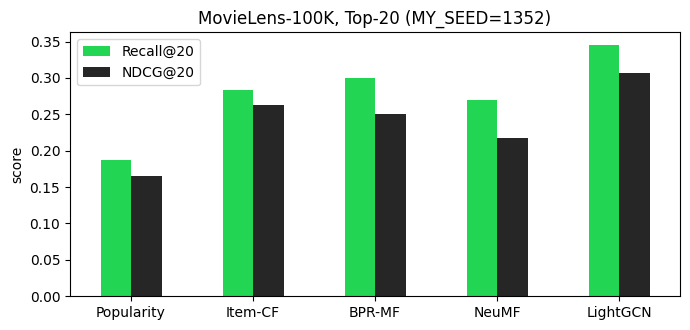

In [15]:
res_df = pd.DataFrame(results).T
display(res_df.style.format("{:.4f}").highlight_max(color="#D3F7DD"))

ax = res_df.plot.bar(figsize=(7, 3.4), color=["#22D654", "#262626"], rot=0)
ax.set_title("MovieLens-100K, Top-%d (MY_SEED=%s)" % (TOPK, MY_SEED)); ax.set_ylabel("score")
plt.tight_layout(); plt.show()

#### 👀 7-1. 내 시드의 사용자에게 무엇이 추천됐는지 보기

In [16]:
show_u = sorted(test_items.keys())[MY_SEED % len(test_items)]
print("사용자 %d 가 학습 때 본 영화 (일부):" % show_u, [idx2title[i] for i in list(train_items[show_u])[:6]])
print("숨겨둔 정답 (test):", [idx2title[i] for i in test_items[show_u]][:6])
for name, mdl in [("BPR-MF", mf), ("LightGCN", lgcn)]:
    sc = mdl.full_scores(torch.tensor([show_u], device=device))[0].detach().cpu()
    sc[list(train_items[show_u])] = -float("inf")
    top = torch.topk(sc, 5).indices.tolist()
    print("\n[%s] Top-5:" % name)
    for r, i in enumerate(top, 1):
        print("  %d. %s %s" % (r, idx2title[i], "✓ 정답" if i in test_items[show_u] else ""))

사용자 416 가 학습 때 본 영화 (일부): ['Toy Story', 'Four Rooms', 'Copycat', 'Usual Suspects, The', "Mr. Holland's Opus", 'My Own Private Idaho']
숨겨둔 정답 (test): ['Stand by Me', 'Bullets Over Broadway', 'Seven (Se7en)', 'Long Kiss Goodnight, The', 'Fish Called Wanda, A', 'Platoon']

[BPR-MF] Top-5:
  1. Seven (Se7en) ✓ 정답
  2. Monty Python and the Holy Grail ✓ 정답
  3. Star Wars 
  4. Return of the Jedi 
  5. Conan the Barbarian 

[LightGCN] Top-5:
  1. Star Wars 
  2. Empire Strikes Back, The 
  3. Raiders of the Lost Ark 
  4. Monty Python and the Holy Grail ✓ 정답
  5. Indiana Jones and the Last Crusade 


#### 📝 서술형 문제 2
1. 7장의 표에서 다섯 결과(Popularity(인기순), Item-CF, BPR-MF, NeuMF, LightGCN)를 Recall@20 기준으로 순서대로 나열하고 숫자를 인용하세요.
2. **인기순 추천이 생각보다 강하게 나왔다면(또는 약하게 나왔다면)** 그 이유를 1장의 Long-tail 결과와 연결해 설명하세요.
3. 세션 21p는 "잘 튜닝한 MF가 NCF를 이기기도 한다(Rendle et al., 2020)"고 했습니다. 본인 결과에서 BPR-MF와 NeuMF 중 무엇이 더 좋았나요? 같은 epoch, 같은 학습률로 비교한 이 실험이 **공정한 비교인지** 한 가지 이상의 근거로 판단하세요.

답1: LightGCN이 가장 높은 성능을 보였으며, 인기순 추천인 Popularity가 가장 낮았다.

답2: Popularity의 Recall@20은 0.1870으로, 비교한 다섯 모델 중 가장 낮았다. 1장의 Long-tail 그래프에서는 소수의 인기 영화에 상호작용이 집중되어 있었다. 이러한 분포에서는 인기 영화 위주로 추천하는 것만으로도 일부 정답을 맞힐 수 있다. 그러나 사용자마다 선호하는 영화가 다르고, 인기 상위 영화 외에도 다양한 영화에 대한 상호작용이 존재한다. Popularity는 이미 본 영화를 제외하는 것 외에는 개인의 취향을 반영하지 않으므로, 사용자별 상호작용 패턴을 활용하는 다른 모델보다 성능이 낮았다고 해석할 수 있다.

답3: BPR-MF의 Recall@20은 0.2999로 NeuMF의 0.2692보다 0.0307 높았다. NDCG@20 역시 BPR-MF가 0.2507, NeuMF가 0.2181로 BPR-MF가 더 높았다. 따라서 이번 실험에서는 신경망을 사용하는 NeuMF보다 내적 기반의 BPR-MF가 좋은 성능을 보였다. 동일한 데이터 분할과 평가 방식, BPR 손실, epoch 수, 학습률을 사용했다는 점에서 실험 조건을 통제한 비교라고 볼 수 있다. 다만 모델마다 구조와 파라미터 수, 수렴 속도가 다르므로 같은 epoch와 학습률이 각 모델에 똑같이 적합하다고 볼 수는 없다. 특히 NeuMF가 충분히 학습되었는지, 설정이 적절했는지는 이번 결과만으로 판단하기 어렵다. 따라서 이번 실험은 주어진 공통 설정에서 BPR-MF가 우수했다는 근거이며, BPR-MF가 항상 NeuMF보다 우수하다는 결론으로 일반화할 수는 없다. 각 모델의 잠재적 성능을 비교하려면 별도의 검증 데이터에서 비슷한 튜닝 예산으로 설정을 선택하고, 여러 시드에서 결과를 확인해야 한다.

#### 📝 서술형 문제 3
LightGCN과 BPR-MF는 학습 파라미터 수가 같습니다(6장 확인 셀 출력 인용). 그런데도 성능이 다르게 나왔다면, 그 차이는 **어디에서** 온 것인가요? 6장의 전파 식과 세션 30p("3층이면 매트릭스(3-hop)의 정보까지 반영")를 연결해 설명하세요.

답: 6장의 출력에서 BPR-MF와 LightGCN의 학습 파라미터 수는 각각 **152896개**로 동일했다. 두 모델 모두 사용자와 영화의 초기 임베딩을 학습하며, LightGCN은 전파 과정에서 별도의 학습 가중치 행렬을 추가하지 않기 때문이다. 그러나 Recall@20은 BPR-MF가 0.2999, LightGCN이 0.3454로 LightGCN이 0.0455 높았다.

이 차이는 임베딩에 그래프의 이웃 정보를 반영하는 방식에서 나온다고 해석할 수 있다. BPR-MF는 학습된 사용자 벡터와 영화 벡터를 직접 내적해 점수를 계산한다. 반면 LightGCN은 정규화 인접행렬 Â를 사용하여 **E⁽ᵏ⁺¹⁾ = ÂE⁽ᵏ⁾** 방식으로 이웃의 정보를 모은다. 연결된 두 노드 사이의 가중치는 연결 수에 따라 1/√(dᵤdᵢ)로 정해지며, 이 가중치 자체는 학습 파라미터가 아니다.

사용자 노드에서 보면 1층에서는 직접 연결된 영화, 2층에서는 그 영화를 함께 본 다른 사용자, 3층에서는 그 사용자들이 본 영화의 정보까지 전달받는다. 따라서 세션의 ‘3층이면 매트릭스의 정보까지 반영된다’는 설명은 해당 영화가 사용자로부터 3-hop 경로로 연결되어 있어 그 정보가 전파될 수 있다는 의미이다.

또한 LightGCN은 마지막 층만 사용하는 것이 아니라 0층부터 3층까지의 임베딩을 평균 내어, 초기 임베딩과 여러 거리의 이웃 정보를 함께 활용한다. 이번 실험의 성능 향상은 파라미터 수의 증가가 아니라, 이러한 그래프 전파와 층 평균을 통해 사용자–영화의 연결 구조를 활용한 데서 비롯된 것으로 해석할 수 있다.

# 🔍 Part B. 세션의 주장을 검증하기 (심화 선택)

> ⚠️ 아래 실험은 **세션 슬라이드와 다른 결과가 나올 수 있습니다.** 그래도 그대로 보고하고 원인을 추론하세요.
> 시간 여유가 있다면 `MY_SEED`를 바꿔 한두 번 더 돌려 보고, 결론이 시드에 따라 흔들리는지도 확인하면 좋습니다.

### 🧱 8. 층은 깊을수록 좋을까? - 층 수 실험 & Over-smoothing 측정

세션 41p는 "Gowalla 실험에서는 3층 이후 개선이 작았다"고 했습니다. 이 데이터에서는 어떨까요?
**0층**은 전파가 없으므로 사실상 **BPR-MF와 같은 모델**입니다.

#### ✏️ ===== TODO 11 =====
Over-smoothing을 숫자로 재기 위해, 벡터들이 서로 얼마나 비슷해졌는지 **평균 cosine 유사도**를 구하는 함수를 완성하세요.

0층: {'Recall@20': 0.29615500905846104, 'NDCG@20': 0.2541922753245091} (4초)
1층: {'Recall@20': 0.3467547184796539, 'NDCG@20': 0.30278606673980535} (6초)
2층: {'Recall@20': 0.35940595584400753, 'NDCG@20': 0.3179491521577363} (8초)
3층: {'Recall@20': 0.35073662982441206, 'NDCG@20': 0.3111206059769316} (9초)
4층: {'Recall@20': 0.3357866175554198, 'NDCG@20': 0.29875187376211526} (11초)


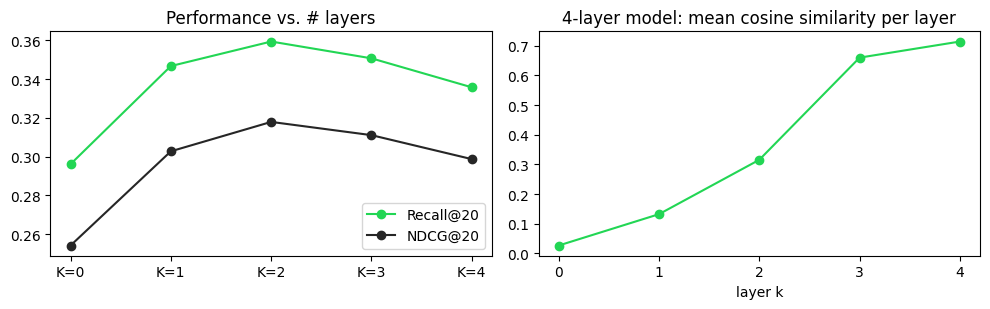

,Recall@20,NDCG@20
K=0,0.2962,0.2542
K=1,0.3468,0.3028
K=2,0.3594,0.3179
K=3,0.3507,0.3111
K=4,0.3358,0.2988


In [17]:
def mean_cosine(E, n_sample=500):
    idx = torch.randperm(E.size(0))[:n_sample]
    sampled = F.normalize(E[idx], p=2, dim=1)
    sim = sampled @ sampled.T

    n = sampled.size(0)
    if n < 2:
        return 0.0

    return ((sim.sum() - sim.diagonal().sum()) / (n * (n - 1))).item()
    # ==================


layer_res, cos_by_layer = {}, None
for K in [0, 1, 2, 3, 4]:
    t0 = time.time()
    m, _ = train_model(LightGCN(n_layers=K), verbose=False)
    layer_res["K=%d" % K] = evaluate(m.full_scores)
    print("%d층: %s (%.0f초)" % (K, layer_res["K=%d" % K], time.time() - t0))
    if K == 4:
        with torch.no_grad():
            cos_by_layer = [mean_cosine(E.detach().cpu()) for E in m.layer_embs()]

layer_df = pd.DataFrame(layer_res).T
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
layer_df.plot(ax=axs[0], marker="o", color=["#22D654", "#262626"]); axs[0].set_title("Performance vs. # layers")
axs[1].plot(range(5), cos_by_layer, marker="o", color="#22D654"); axs[1].set_xticks(range(5))
axs[1].set_title("4-layer model: mean cosine similarity per layer"); axs[1].set_xlabel("layer k")
plt.tight_layout(); plt.show()
display(layer_df.style.format("{:.4f}"))

#### 📝 서술형 문제 4
1. 본인 결과에서 성능이 가장 좋았던 층 수와, 0층(≈ MF) 대비 향상 폭을 인용하세요.
2. 오른쪽 그래프에서 층이 깊어질수록 평균 cosine 유사도가 어떻게 변했나요? 이것이 세션 31p의 Over-smoothing과 같은 현상인지 판단하세요.
3. LightGCN이 마지막 층만 쓰지 않고 **층 평균**을 쓰는 이유를, 이 두 그래프를 근거로 설명하세요.

답1: 이번 실험에서는 2층(K=2)에서 Recall@20이 0.3594, NDCG@20이 0.3179로 두 지표 모두 가장 높았다. 0층의 Recall@20은 0.2962, NDCG@20은 0.2542였으므로, 표시된 값을 기준으로 각각 0.0632, 0.0637 향상되었다. 그러나 3층부터 성능이 감소하여 4층에서는 Recall@20이 0.3358, NDCG@20이 0.2988로 낮아졌다. 따라서 이번 데이터와 실험 설정에서는 층을 깊게 쌓을수록 성능이 좋아지는 것은 아니었다.

답2: 오른쪽 그래프는 학습된 4층 모델 내부의 층별 임베딩을 비교한 것이다. 평균 코사인 유사도는 그래프상 0층에서 약 0.03, 1층에서 약 0.14, 2층에서 약 0.32, 3층에서 약 0.66, 4층에서 약 0.71로 증가했다. 이는 전파를 반복할수록 서로 다른 노드의 벡터가 비슷해지는 경향을 보여주며, 세션에서 설명한 Over-smoothing과 부합한다.

왼쪽 그래프에서도 2층 이후 성능이 감소했으므로, 과도한 전파로 사용자와 영화의 구별에 필요한 정보가 약해졌을 가능성이 있다. 다만 왼쪽은 층 수가 다른 모델들을 각각 학습한 결과이고, 오른쪽은 하나의 4층 모델 내부를 분석한 결과이다. 따라서 두 그래프는 Over-smoothing 가능성을 뒷받침하지만, 성능 하락의 원인이 그것 하나뿐이라고 단정할 수는 없다.

답3: 초기 임베딩과 얕은 층은 노드 고유의 정보와 가까운 이웃 정보를 담고, 깊은 층은 더 멀리 있는 이웃의 정보를 반영한다. 이번 결과처럼 깊은 층에서 벡터들이 지나치게 비슷해지면, 마지막 층만 사용할 경우 노드 간 차이가 약해진 표현에 의존할 수 있다. 따라서 LightGCN은 여러 층의 임베딩을 평균 내어 다양한 거리의 정보를 함께 활용하고, 초기·얕은 층의 정보도 최종 표현에 남긴다.

다만 이번 실험은 모든 모델에 층 평균을 적용했으며, 마지막 층만 사용하는 방식과 직접 비교하지는 않았다. 또한 층 평균을 사용한 상태에서도 3층 이후 성능이 감소했으므로, 층 평균이 과도한 전파의 영향을 완전히 없애는 것은 아니며 적절한 층 수를 선택하는 것이 중요하다.

### ⚖️ 9. W와 σ를 다시 넣으면? - LightGCN vs NGCF 스타일

세션 38p: "ID와 상호작용만 쓰는 협업 필터링 **실험에서는** W와 σ를 뺀 쪽이 더 나았다."
LightGCN의 매 층에 **선형 변환 W와 활성화 함수 σ(LeakyReLU)** 를 다시 넣어 직접 비교합니다.

#### ✏️ ===== TODO 12 =====

In [18]:
class LightGCNWithW(LightGCN):
    def __init__(self, n_layers=N_LAYERS):
        super().__init__(n_layers)
        self.W = nn.ModuleList([nn.Linear(EMB_DIM, EMB_DIM) for _ in range(n_layers)])

    def layer_embs(self):
        # ===== TODO 12 =====
        layers = [self.emb.weight]

        for k in range(self.n_layers):
            propagated = torch.sparse.mm(self.A, layers[-1])
            transformed = self.W[k](propagated)
            layers.append(F.leaky_relu(transformed, negative_slope=0.2))

        return layers
        # ==================
        # ==================


t0 = time.time()
lgcn_w, _ = train_model(LightGCNWithW())
results_w = {"LightGCN": results["LightGCN"], "LightGCN + W + sigma": evaluate(lgcn_w.full_scores)}
display(pd.DataFrame(results_w).T.style.format("{:.4f}"))
print("(%.0f초)" % (time.time() - t0))

epoch  10 | loss 0.2664 | Recall@20 0.2580 | NDCG@20 0.2263
epoch  20 | loss 0.2222 | Recall@20 0.2913 | NDCG@20 0.2507
epoch  30 | loss 0.1991 | Recall@20 0.3128 | NDCG@20 0.2754
epoch  40 | loss 0.1774 | Recall@20 0.3200 | NDCG@20 0.2866
epoch  50 | loss 0.1675 | Recall@20 0.3307 | NDCG@20 0.2908


,Recall@20,NDCG@20
LightGCN,0.3454,0.3072
LightGCN + W + sigma,0.3307,0.2908


(10초)


#### 📝 서술형 문제 5
1. W와 σ를 넣은 모델이 더 좋았나요, 나빴나요? 숫자를 인용하세요.
2. 결과가 세션 38p와 **같았다면** 그 이유를, **달랐다면** 가능한 원인(epoch 수, 학습률, 데이터 크기 등)을 추론하세요.
3. 만약 영화에 장르, 줄거리 같은 **콘텐츠 특징**이 있었다면, W의 역할이 어떻게 달라질 수 있을지 생각해 보세요.

(여기에 답)

답1. 기존 LightGCN의 Recall@20은 0.3454, NDCG@20은 0.3072였으며, W와 σ를 추가한 모델은 각각 0.3307, 0.2908이었다. 따라서 W와 σ를 추가했을 때 Recall@20은 0.0147, NDCG@20은 0.0164 감소하여 두 지표 모두 성능이 낮아졌다.

답2. 이번 결과는 ID와 상호작용만 사용하는 협업 필터링 실험에서 W와 σ를 제거한 모델이 더 좋았다는 세션의 설명과 일치하는 방향이다. 이 실험의 입력은 장르나 줄거리 같은 콘텐츠 특징이 아니라 학습 가능한 ID 임베딩이다. 초기 임베딩 자체를 추천 목적에 맞게 학습할 수 있으므로, 추가적인 선형 변환과 비선형 활성화가 반드시 필요한 것은 아니다. 오히려 파라미터와 연산이 늘어나 최적화가 어려워지거나 과적합 가능성이 커졌을 수 있다.

다만 이번 결과만으로 성능 하락의 원인을 확정할 수는 없다. W와 σ를 추가한 모델은 50 epoch까지 평가 성능이 계속 상승했으므로, 학습이 충분하지 않았을 가능성도 있다. 동일한 학습률과 epoch 수가 두 모델에 모두 적합하다고 볼 수 없으며, 현재 결과는 주어진 설정에서 기본 LightGCN이 더 우수했다는 의미로 해석해야 한다.


답3. 영화에 장르나 줄거리 같은 콘텐츠 특징이 있다면, W는 이러한 특징을 추천에 적합한 표현 공간으로 변환하고 여러 특징을 조합하는 역할을 할 수 있다. 예를 들어 줄거리 벡터에서 사용자 선호와 관련된 정보를 추출하거나, 콘텐츠 특징을 협업 필터링 임베딩과 결합하기 좋은 차원으로 변환할 수 있다. 따라서 콘텐츠 특징을 활용하는 상황에서는 W가 더 유용할 수 있다. 다만 현재 코드에는 콘텐츠 특징을 입력하는 과정이 없으므로, 이를 활용하려면 모델 구조를 확장하고 별도의 실험으로 효과를 확인해야 한다.

### 📈 10. 정규화는 인기 편향을 줄일까? - 추천 결과의 인기도 분석

세션 39p는 "차수에 따라 정보 전달 크기를 조절할 뿐, 이것만으로 인기 편향이 해결되지는 않는다"고 했습니다. **직접 재 봅시다.**

#### ✏️ ===== TODO 13 =====
모델별 추천 목록(사용자당 Top-20)에서 두 가지를 구하세요.
- **평균 인기도**: 추천된 영화들의 학습 데이터 상호작용 수(`pop`) 평균
- **Long-tail 비율**: 추천된 영화 중 인기 상위 20%에 **속하지 않는** 영화의 비율

,avg_popularity,longtail_ratio
Popularity,229.4,0.0%
BPR-MF,128.4,14.6%
NeuMF,129.6,16.2%
LightGCN,150.5,6.3%


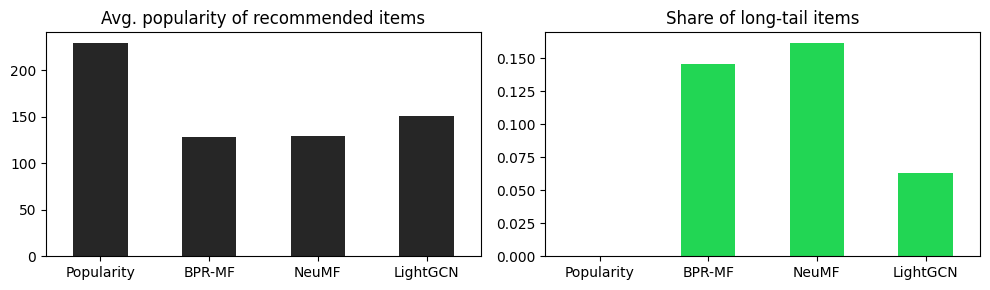

In [19]:
head_items = set(torch.argsort(pop, descending=True)[: int(n_items * 0.2)].tolist())

def popularity_stats(rec_lists):
    all_rec = [i for lst in rec_lists.values() for i in lst]
    # ===== TODO 13 =====
    avg_pop = pop[all_rec].float().mean().item()
    tail_ratio = sum(i not in head_items for i in all_rec) / len(all_rec)
    # ==================
    return {"avg_popularity": avg_pop, "longtail_ratio": tail_ratio}


bias = {}
for name, fn in [("Popularity", lambda users: pop.to(device).unsqueeze(0).repeat(len(users), 1)),
                 ("BPR-MF", mf.full_scores), ("NeuMF", neumf.full_scores), ("LightGCN", lgcn.full_scores)]:
    _, lists = evaluate(fn, return_lists=True)
    bias[name] = popularity_stats(lists)
bias_df = pd.DataFrame(bias).T
display(bias_df.style.format({"avg_popularity": "{:.1f}", "longtail_ratio": "{:.1%}"}))

fig, axs = plt.subplots(1, 2, figsize=(10, 3))
bias_df["avg_popularity"].plot.bar(ax=axs[0], color="#262626", rot=0, title="Avg. popularity of recommended items")
bias_df["longtail_ratio"].plot.bar(ax=axs[1], color="#22D654", rot=0, title="Share of long-tail items")
plt.tight_layout(); plt.show()

#### 📝 서술형 문제 6
1. LightGCN의 추천은 BPR-MF보다 인기작 쪽으로 더 치우쳤나요, 덜 치우쳤나요? 두 지표를 인용하세요.
2. 결과를 근거로 "LightGCN의 정규화는 인기 편향을 해결한다"는 문장이 맞는지 판단하세요.
3. 정확도(7장)와 다양성(10장) 사이에 **트레이드오프**가 보였다면, 실제 서비스라면 어떤 기준으로 모델을 고르겠는지 한두 문장으로 적으세요.

(여기에 답)

답1. LightGCN이 추천한 영화의 평균 인기도는 150.5로, BPR-MF의 128.4보다 22.1 높았다. 반면 Long-tail 비율은 LightGCN이 6.3%, BPR-MF가 14.6%로 LightGCN이 8.3%p 낮았다. 즉, LightGCN은 평균적으로 상호작용이 더 많은 영화를 추천했고, 인기 상위 20% 밖의 영화는 더 적게 추천했다. 따라서 이번 실험에서는 LightGCN이 BPR-MF보다 인기작 쪽으로 더 치우쳤다고 판단할 수 있다.

답2. 이번 결과는 정규화만으로 인기 편향이 해결된다는 주장을 뒷받침하지 않는다. LightGCN의 정규화는 연결된 노드들의 차수에 따라 각 연결의 정보 전달 가중치를 조절한다. 그러나 이는 비인기 영화의 추천 비율을 직접 높이거나 인기 편향을 제거하도록 학습하는 것은 아니다. 인기 영화는 여전히 많은 사용자와 연결되어 있어 여러 경로로 정보를 주고받을 수 있다.

실제로 정규화를 사용하는 LightGCN에서도 추천의 93.7%가 인기 상위 20% 영화에 집중되었다. 다만 이번 실험에는 정규화를 제거한 LightGCN과의 비교가 없으므로, 정규화 자체가 편향을 얼마나 줄였는지 또는 늘렸는지는 판단할 수 없다. 확인할 수 있는 것은 정규화를 적용하더라도 인기 편향이 남아 있다는 점이다.

답3. LightGCN은 BPR-MF보다 Recall@20이 높았지만(0.3454 대 0.2999), Long-tail 비율은 낮아(6.3% 대 14.6%) 정확도와 비인기 영화 노출 사이의 트레이드오프가 나타났다. 실제 서비스에서는 정확도를 우선하면 LightGCN을 선택하되 새로운 영화의 발견도 중요하다면 BPR-MF를 고려하거나 LightGCN의 추천 목록을 재정렬해 비인기 영화의 노출을 보완하겠으며, Long-tail 비율만으로 장르 등 모든 측면의 다양성을 판단하지는 않겠다.

#### 🤔 회고

Part A에서 겪은 어려움과 해결 과정을 3-5문장으로 적습니다. 끝까지 헷갈린 개념 1-3개도 함께: (여기에 답)
Part A에서는 추천 모델의 수식을 코드로 옮기고 각 연산의 의미를 연결하는 과정이 어려웠다. TODO를 하나씩 구현한 뒤 확인 셀과 실행 결과를 대조하면서, BPR 손실은 본 영화와 비교 대상 영화의 점수 차이를 학습하고 LightGCN은 이웃 정보를 전파한다는 흐름을 정리했다. 실험에서는 구조가 더 복잡한 NeuMF가 BPR-MF보다 낮은 성능을 보여, 모델의 복잡성이 성능 향상을 보장하지 않는다는 점을 배웠다. 끝까지 주의해서 구분해야 했던 개념은 ‘관측되지 않은 영화와 싫어하는 영화의 차이’, ‘정규화와 인기 편향 해소의 차이’, ‘코사인 유사도 증가와 성능 하락의 인과관계’였다.


Part B(심화 선택)를 진행했다면, 세션 내용과 **다르게 나온 결과**와 그로부터 배운 점을 이어서 적어도 좋습니다: (여기에 답)
Part B에서는 세션에서 소개한 Gowalla의 층 수 실험과 달리, 이번 MovieLens 실험에서는 2층에서 성능이 가장 높고 이후 감소했다. W와 σ를 추가하면 성능이 낮아진다는 점은 세션과 같은 방향이었지만, 이것만으로 해당 연산이 모든 상황에서 불필요하다고 일반화할 수는 없었다. 또한 LightGCN이 정확도는 가장 높았지만 BPR-MF보다 인기작에 치우쳐, 정확도와 비인기 영화 노출을 함께 살펴봐야 한다는 점을 배웠다.

#### ⚙️ 생성형 AI 활용 (비판적 사용)

AI는 **검산기, 설명 도우미**로 활용하고 최종 판단은 본인이 합니다.

- **어디에 썼나** (PyTorch 문법 디버깅, 개념 설명, 에러 해석 등 구체적으로): PyTorch 문법과 각 연산의 의미를 설명받았다. 구체적으로 Recall·NDCG 계산, Jaccard 유사도의 브로드캐스팅, Negative Sampling, BPR 손실, LightGCN의 정규화와 전파 등을 구현하는 데 도움을 받았다.

- **AI가 이 실험에는 틀린 답을 준 사례**
  본인이 겪은 사례와, 그것을 **어떻게 알아채고 고쳤는지**(본인 출력값과 대조 / 공식 문서 확인 / 직접 실험) 적으세요: 이번 대화와 실행 과정에서 명확하게 확인한 AI 코드 오답 사례는 없었다. 따라서 실제로 겪지 않은 오류와 수정 과정을 만들어 적지는 않았다. 대신 AI가 제시한 코드가 확인 셀을 통과하는지 점검하고, 서술형 답안에 사용된 수치가 실제 출력과 일치하는지 대조했다. 다만 확인 셀 통과만으로 모든 구현과 해석이 완전히 검증되는 것은 아니므로, ‘정규화가 인기 편향을 해결한다’처럼 결과를 넘어서는 일반화를 하지 않도록 주의했다.

- **실제 대화 내역** 붙여넣기:

```
ChatGPT:
“이번 결과에서는 LightGCN이 BPR-MF보다 정확도는 높지만, 인기작 쪽으로 더 치우쳤어요.”
```

- 마지막 한 문장: **AI가 대신할 수 없었던 나만의 판단**은 무엇이었나요? 실제 서비스에서 정확도와 새로운 영화 발견 중 무엇을 더 중요하게 볼지는, 실험 결과를 이해한 뒤 서비스의 목적에 맞게 내가 결정해야 하는 판단이다.

#### 📚 참고 자료

**Part A**
- BPR: Rendle et al., [BPR: Bayesian Personalized Ranking from Implicit Feedback](https://arxiv.org/abs/1205.2618) (UAI 2009)
- NCF: He et al., [Neural Collaborative Filtering](https://arxiv.org/abs/1708.05031) (WWW 2017)
- LightGCN: He et al., [LightGCN: Simplifying and Powering Graph Convolution Network for Recommendation](https://arxiv.org/abs/2002.02126) (SIGIR 2020)
- MovieLens: Harper & Konstan, [The MovieLens Datasets: History and Context](https://dl.acm.org/doi/10.1145/2827872) (ACM TiiS 2015)

**Part B**
- NGCF: Wang et al., [Neural Graph Collaborative Filtering](https://arxiv.org/abs/1905.08108) (SIGIR 2019)
- MF vs NCF 재검증: Rendle et al., [Neural Collaborative Filtering vs. Matrix Factorization Revisited](https://arxiv.org/abs/2005.09683) (RecSys 2020)
- 강의 자료: [Stanford CS224W](https://web.stanford.edu/class/cs224w/)